PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
def plot_correlation_matrix(df, threshold=0.75):
    """
    Plots a heatmap showing only strong positive or negative correlations (|r| >= threshold).

    Parameters:
    - df (pd.DataFrame): The input DataFrame.
    - threshold (float): Absolute correlation threshold to display (default: 0.75).
    """
    corr = df.corr()

    # Keep only strong correlations, zero-out weak ones (keeps signs intact)
    filtered_corr = corr.where(corr.abs() >= threshold)

    plt.figure(figsize=(18, 13))
    sns.heatmap(filtered_corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True,
                mask=filtered_corr.isnull(), square=True, linewidths=0.5, linecolor='gray')
    plt.title(f'Correlation Heatmap (|r| ≥ {threshold})')
    plt.tight_layout()
    plt.show()

In [3]:
merged_df = pd.read_csv("Data/uncleaned_merged_df.csv")

In [4]:
merged_df.columns

Index(['id', 'Shots On Target', 'DEEP', 'PPDA', 'shots', 'xG', 'yellow_card',
       'red_card', 'key_passes', 'xA',
       ...
       'Big chances_agg', 'Fouled in final third_agg', 'Tackles won_agg',
       'Dribbles_agg', 'Crosses_agg', 'Long balls_agg', 'Yellow cards_agg',
       'Offsides_agg', 'Goalkeeper saves_agg', 'date'],
      dtype='object', length=135)

In [5]:
sofa_org= ['Corner kicks', 'Fouls', 'Shots off target',
       'Throw-ins', 'Ground duels', 'Aerial duels','Game dominance',
       'Blocked per shots on target', 'Shots on target per total shots',
       'Hit woodwork per total shots', 'Shots outside box per total shots',
       'Big chances', 'Fouled in final third', 'Tackles won', 'Dribbles',
       'Crosses', 'Long balls', 'Yellow cards', 'Offsides', 'Goalkeeper saves']
sofa_window= ['Corner kicks_mean', 'Fouls_mean', 'Shots off target_mean',
       'Throw-ins_mean', 'Ground duels_mean', 'Aerial duels_mean',
       'Blocked per shots on target_median','Game dominance_mean',
       'Shots on target per total shots_mean',
       'Hit woodwork per total shots_median',
       'Shots outside box per total shots_mean', 'Big chances_mean',
       'Fouled in final third_mean', 'Tackles won_mean', 'Dribbles_mean',
       'Crosses_mean', 'Long balls_median', 'Yellow cards_mean',
       'Offsides_median', 'Goalkeeper saves_mean']
sofa_agg= ['Corner kicks_agg',
       'Fouls_agg', 'Shots off target_agg', 'Throw-ins_agg',
       'Ground duels_agg', 'Aerial duels_agg',
       'Blocked per shots on target_agg','Game dominance_agg',
       'Shots on target per total shots_agg',
       'Hit woodwork per total shots_agg',
       'Shots outside box per total shots_agg', 'Big chances_agg',
       'Fouled in final third_agg', 'Tackles won_agg', 'Dribbles_agg',
       'Crosses_agg', 'Long balls_agg', 'Yellow cards_agg', 'Offsides_agg',
       'Goalkeeper saves_agg']

In [6]:
original_features = ['Shots On Target', 'DEEP', 'PPDA','shots', 'xG', 'yellow_card', 'red_card',
       'key_passes', 'xA', 'xGChain', 'xGBuildup'] + sofa_org
window_aggregated_features = ['shots_median', 'xG_median',
       'key_passes_median', 'xA_median', 'xGChain_median', 'xGBuildup_median',
       'yellow_card_median', 'red_card_median', 'Shots On Target_mean', 'DEEP_mean', 'PPDA_median'] + sofa_window
model_aggregated_features = ['shots_agg', 'xG_agg',
       'yellow_card_agg', 'red_card_agg', 'key_passes_agg', 'xA_agg',
       'xGChain_agg', 'xGBuildup_agg', 'PPDA_agg', 'Shots On Target_agg', 'DEEP_agg'] + sofa_agg
fifa_features = ['Overall', 'Finishing_adj', 'Shot Power_adj',
       'Long Shots_adj', 'Heading_adj', 'Curve_adj', 'FK Acc._adj',
       'Penalties_adj', 'Short Pass_adj', 'Long Pass_adj', 'Stand Tackle_adj',
       'Interceptions_adj', 'Jumping_adj', 'Stamina_adj', 'Strength_adj',
       'Acceleration_adj', 'Agility_adj', 'Balance_adj', 'GK Handling_adj',
       'GK Kicking_adj', 'GK Positioning_adj', 'Reactions_adj',
       'Att. Position_adj', 'Vision_adj', 'Dribbling_adj',
       'Overall Passing_adj', 'Overall Shooting_adj', 'Overall Defence_adj',
       'Overall Physical_adj', 'Overall Goalkeeper_adj']

elo_features = ["ClubELO", "Seasonal_Elo"]
result_features = ['result']
indexing_features = ['id', 'date']

In [7]:
merged_df.drop(columns=["xA", "xA_median", "xA_agg"], inplace=True)
original_features.remove("xA")
window_aggregated_features.remove("xA_median")
model_aggregated_features.remove("xA_agg")


In [8]:
merged_df.drop(columns=["xGChain", "xGChain_median", "xGChain_agg"], inplace=True)
original_features.remove("xGChain")
window_aggregated_features.remove("xGChain_median")
model_aggregated_features.remove("xGChain_agg")

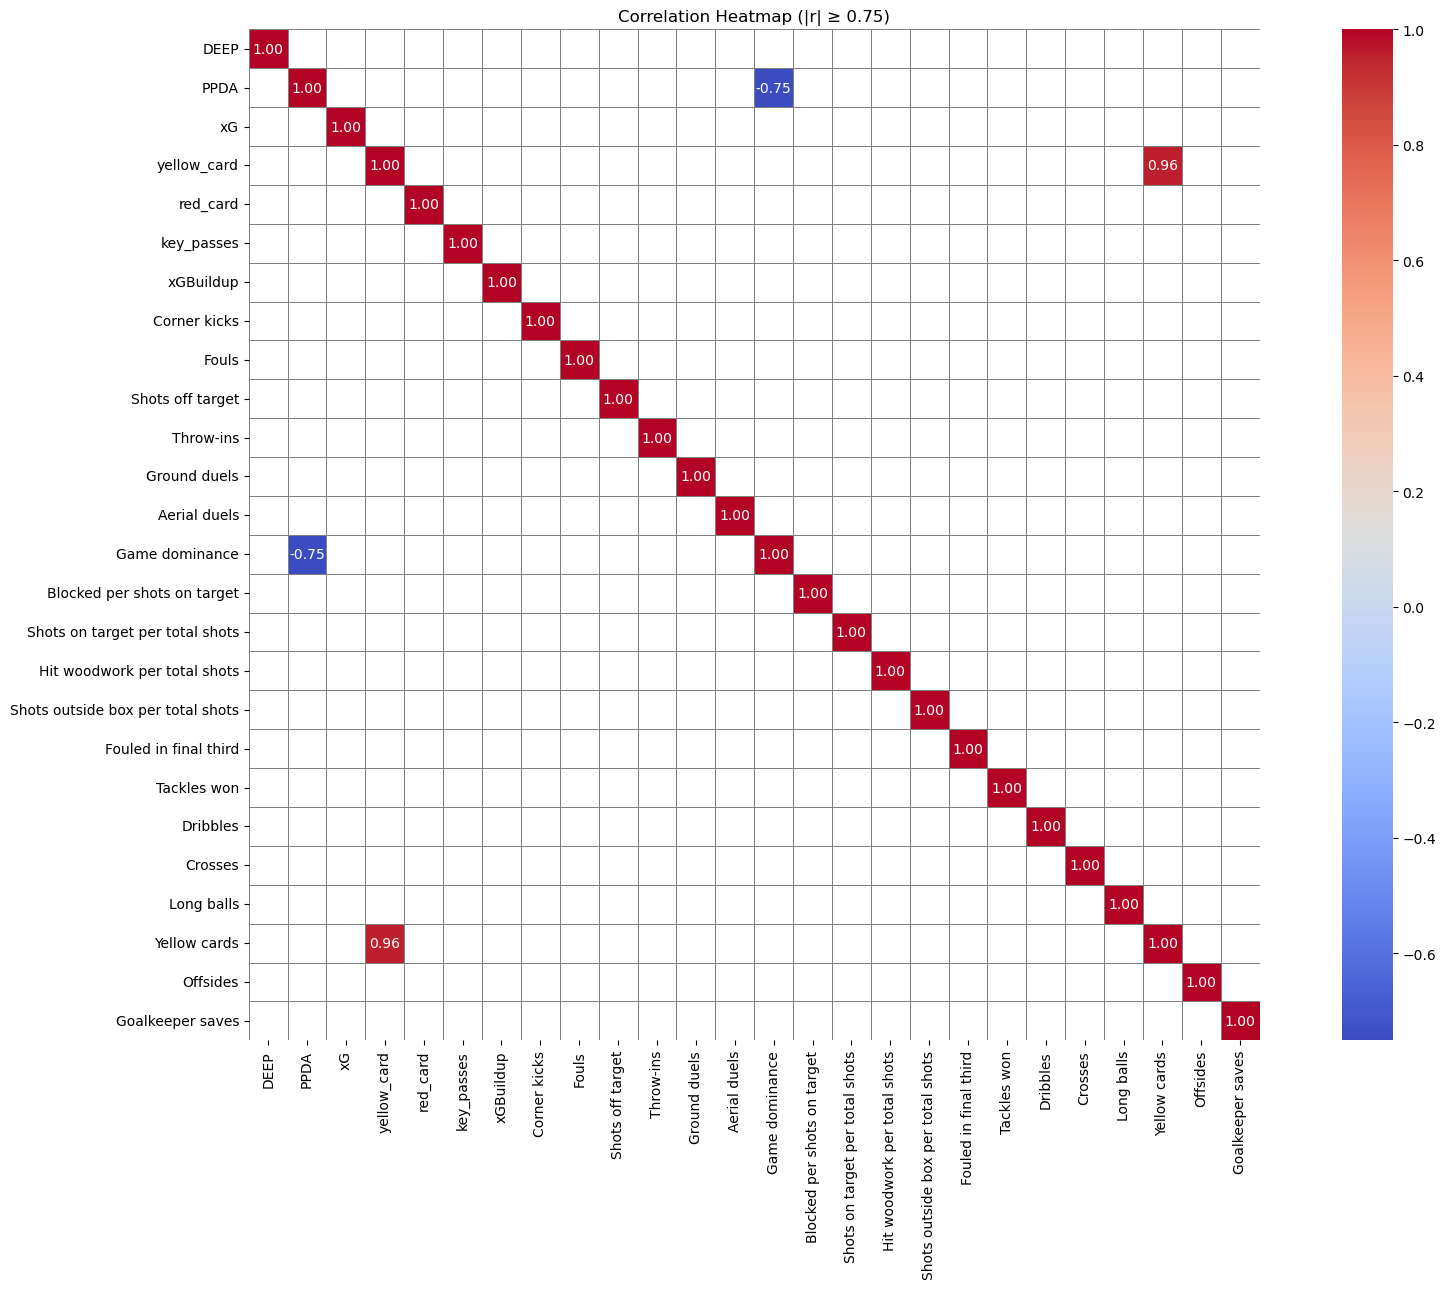

In [15]:
plot_correlation_matrix(merged_df[original_features])

In [10]:

# Drop old columns
merged_df.drop(
    columns=[
        "Shots On Target", "shots",
        "Shots On Target_mean", "shots_median",
        "Shots On Target_agg", "shots_agg",

        "Big chances",
        "Big chances_mean",
        "Big chances_agg",
    ],
    inplace=True
)
original_features.remove("Shots On Target"); original_features.remove("shots")
window_aggregated_features.remove("Shots On Target_mean"); window_aggregated_features.remove("shots_median")
model_aggregated_features.remove("Shots On Target_agg"); model_aggregated_features.remove("shots_agg")

original_features.remove("Big chances")
window_aggregated_features.remove("Big chances_mean")
model_aggregated_features.remove("Big chances_agg")

In [11]:
merged_df.to_csv("Data/cleaned_merged_df.csv", index=False)

In [12]:
original_features

['DEEP',
 'PPDA',
 'xG',
 'yellow_card',
 'red_card',
 'key_passes',
 'xGBuildup',
 'Corner kicks',
 'Fouls',
 'Shots off target',
 'Throw-ins',
 'Ground duels',
 'Aerial duels',
 'Game dominance',
 'Blocked per shots on target',
 'Shots on target per total shots',
 'Hit woodwork per total shots',
 'Shots outside box per total shots',
 'Fouled in final third',
 'Tackles won',
 'Dribbles',
 'Crosses',
 'Long balls',
 'Yellow cards',
 'Offsides',
 'Goalkeeper saves']

In [13]:
window_aggregated_features

['xG_median',
 'key_passes_median',
 'xGBuildup_median',
 'yellow_card_median',
 'red_card_median',
 'DEEP_mean',
 'PPDA_median',
 'Corner kicks_mean',
 'Fouls_mean',
 'Shots off target_mean',
 'Throw-ins_mean',
 'Ground duels_mean',
 'Aerial duels_mean',
 'Blocked per shots on target_median',
 'Game dominance_mean',
 'Shots on target per total shots_mean',
 'Hit woodwork per total shots_median',
 'Shots outside box per total shots_mean',
 'Fouled in final third_mean',
 'Tackles won_mean',
 'Dribbles_mean',
 'Crosses_mean',
 'Long balls_median',
 'Yellow cards_mean',
 'Offsides_median',
 'Goalkeeper saves_mean']

In [14]:
model_aggregated_features

['xG_agg',
 'yellow_card_agg',
 'red_card_agg',
 'key_passes_agg',
 'xGBuildup_agg',
 'PPDA_agg',
 'DEEP_agg',
 'Corner kicks_agg',
 'Fouls_agg',
 'Shots off target_agg',
 'Throw-ins_agg',
 'Ground duels_agg',
 'Aerial duels_agg',
 'Blocked per shots on target_agg',
 'Game dominance_agg',
 'Shots on target per total shots_agg',
 'Hit woodwork per total shots_agg',
 'Shots outside box per total shots_agg',
 'Fouled in final third_agg',
 'Tackles won_agg',
 'Dribbles_agg',
 'Crosses_agg',
 'Long balls_agg',
 'Yellow cards_agg',
 'Offsides_agg',
 'Goalkeeper saves_agg']